# Ανάλυση και Πρόβλεψη Τιμών Πετρελαίου Κίνησης (Diesel) στην Αττική
Αυτό το Notebook αποτελεί ένα ολοκληρωμένο **End-to-End Pipeline Μηχανικής Μάθησης**. 
Σκοπός μας είναι να διαβάσουμε ακατέργαστα δεδομένα (raw text) από πρατήρια καυσίμων, να τα καθαρίσουμε, να ανακαλύψουμε μοτίβα (EDA) και να εκπαιδεύσουμε έναν αλγόριθμο Random Forest για να προβλέπει τις τιμές.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

sns.set_theme(style="whitegrid")

## Φόρτωση και Καθαρισμός Δεδομένων (Data Cleaning)
Διαβάζουμε το αρχικό ακατέργαστο αρχείο `.txt` (όπου έχουμε κάνει επικόλληση και τα σημερινά δεδομένα) και εξάγουμε τις πληροφορίες.
*(Αντικατέστησε το παρακάτω με τον ακριβή κώδικα καθαρισμού που έχεις στο data_cleaning.py, χωρίς την αποθήκευση σε CSV στο τέλος)*

In [2]:

%run data_cleaning.py

display(df.head())

Έμειναν 1325 μοναδικές και καθαρές εγγραφές.
Δείτε το τελικό αποτέλεσμα:
    Τιμή          Προϊόν Εταιρεία                         Διεύθυνση  \
0  1.927  Diesel Κίνησης   REVOIL   ΛΕΩΦΟΡΟΣ ΚΩΝΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 161   
1  1.938  Diesel Κίνησης  SILKOIL          ΠΕΡΙΚΛΕΟΥΣ 39 -ΠΕΡΙΣΤΕΡΙ   
2  1.938  Diesel Κίνησης    ΕΤΕΚΑ  ΣΟΦΟΚΛΗ ΒΕΝΙΖΕΛΟΥ 60 - ΛΥΚΟΒΡΥΣΗ   
3  1.939  Diesel Κίνησης    ΕΤΕΚΑ                ΘΗΒΩΝ 38 ΠΕΡΙΣΤΕΡΙ   
4  1.949  Diesel Κίνησης    ΕΤΕΚΑ             ΚΩΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 133   

       Ημερομηνία  
0  02/10 14:24:51  
1  16/10 09:50:59  
2  13/10 08:37:07  
3  17/10 13:48:48  
4  16/10 17:13:01  


,Τιμή,Προϊόν,Εταιρεία,Διεύθυνση,Ημερομηνία
0,1.927,Diesel Κίνησης,REVOIL,ΛΕΩΦΟΡΟΣ ΚΩΝΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 161,02/10 14:24:51
1,1.938,Diesel Κίνησης,SILKOIL,ΠΕΡΙΚΛΕΟΥΣ 39 -ΠΕΡΙΣΤΕΡΙ,16/10 09:50:59
2,1.938,Diesel Κίνησης,ΕΤΕΚΑ,ΣΟΦΟΚΛΗ ΒΕΝΙΖΕΛΟΥ 60 - ΛΥΚΟΒΡΥΣΗ,13/10 08:37:07
3,1.939,Diesel Κίνησης,ΕΤΕΚΑ,ΘΗΒΩΝ 38 ΠΕΡΙΣΤΕΡΙ,17/10 13:48:48
4,1.949,Diesel Κίνησης,ΕΤΕΚΑ,ΚΩΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 133,16/10 17:13:01


## Μηχανική Χαρακτηριστικών (Feature Engineering)
Εκτελούμε το εξωτερικό αρχείο εμπλουτισμού για να δημιουργήσουμε τις απαραίτητες μεταβλητές (Περιοχή, Premium, Λεωφόρος κ.λπ.) για την ανάλυση και το μοντέλο.

In [3]:
%run feature_engineering.py

display(df.head())

Η Μηχανική Χαρακτηριστικών ολοκληρώθηκε!

Δείγμα των νέων στηλών:
                                  Διεύθυνση    Περιοχή      Ημερομηνία  Ώρα
0           ΛΕΩΦΟΡΟΣ ΚΩΝΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 161    ΑΓΝΩΣΤΟ  02/10 14:24:51   14
1                  ΠΕΡΙΚΛΕΟΥΣ 39 -ΠΕΡΙΣΤΕΡΙ  ΠΕΡΙΣΤΕΡΙ  16/10 09:50:59    9
2          ΣΟΦΟΚΛΗ ΒΕΝΙΖΕΛΟΥ 60 - ΛΥΚΟΒΡΥΣΗ  ΛΥΚΟΒΡΥΣΗ  13/10 08:37:07    8
3                        ΘΗΒΩΝ 38 ΠΕΡΙΣΤΕΡΙ  ΠΕΡΙΣΤΕΡΙ  17/10 13:48:48   13
4                     ΚΩΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 133    ΑΓΝΩΣΤΟ  16/10 17:13:01   17
5              ΛΕΩΦΟΡΟΣ ΣΧΙΣΤΟΥ & ΠΑΛΑΣΚΑ 1    ΑΓΝΩΣΤΟ  17/10 13:58:28   13
6              ΛΕΩΦΟΡΟΣ ΣΧΙΣΤΟΥ & ΠΑΛΑΣΚΑ 1    ΑΓΝΩΣΤΟ  17/10 13:58:21   13
7  ΗΡΑΚΛΕΙΤΟΥ 17-19 & ΚΛΕΙΣΟΥΡΑΣ - ΧΑΛΑΝΔΡΙ   ΧΑΛΑΝΔΡΙ  17/10 10:39:35   10
8                           ΛΕΩΦ ΣΧΙΣΤΟΥ 10    ΑΓΝΩΣΤΟ  06/10 13:32:43   13
9                ΛΕΩΦ. ΑΘΗΝΩΝ 362 - ΧΑΪΔΑΡΙ    ΧΑΪΔΑΡΙ  06/10 13:23:57   13


C:\ml project\feature_engineering.py:26: SyntaxWarning: invalid escape sequence '\.'
  highway_keywords = 'ΛΕΩΦ|Λ\.|Ε\.Ο\.|ΧΛΜ'


,Τιμή,Προϊόν,Εταιρεία,Διεύθυνση,Ημερομηνία,Ώρα,Περιοχή,Είναι_Premium,Ημέρα,Σε_Λεωφόρο
0,1.927,Diesel Κίνησης,REVOIL,ΛΕΩΦΟΡΟΣ ΚΩΝΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 161,02/10 14:24:51,14,ΑΓΝΩΣΤΟ,False,02/10 14:24:51,True
1,1.938,Diesel Κίνησης,SILKOIL,ΠΕΡΙΚΛΕΟΥΣ 39 -ΠΕΡΙΣΤΕΡΙ,16/10 09:50:59,9,ΠΕΡΙΣΤΕΡΙ,False,16/10 09:50:59,False
2,1.938,Diesel Κίνησης,ΕΤΕΚΑ,ΣΟΦΟΚΛΗ ΒΕΝΙΖΕΛΟΥ 60 - ΛΥΚΟΒΡΥΣΗ,13/10 08:37:07,8,ΛΥΚΟΒΡΥΣΗ,False,13/10 08:37:07,False
3,1.939,Diesel Κίνησης,ΕΤΕΚΑ,ΘΗΒΩΝ 38 ΠΕΡΙΣΤΕΡΙ,17/10 13:48:48,13,ΠΕΡΙΣΤΕΡΙ,False,17/10 13:48:48,False
4,1.949,Diesel Κίνησης,ΕΤΕΚΑ,ΚΩΣΤΑΝΤΙΝΟΥΠΟΛΕΩΣ 133,16/10 17:13:01,17,ΑΓΝΩΣΤΟ,False,16/10 17:13:01,False


## Στατιστική Ανάλυση (Exploratory Data Analysis - EDA)
Ας δημιουργήσουμε ένα ταμπλό ελέγχου για να δούμε πώς κατανέμονται οι τιμές ανάλογα με την περιοχή, την τοποθεσία (λεωφόρος/συνοικία) και το μέγεθος της εταιρείας.

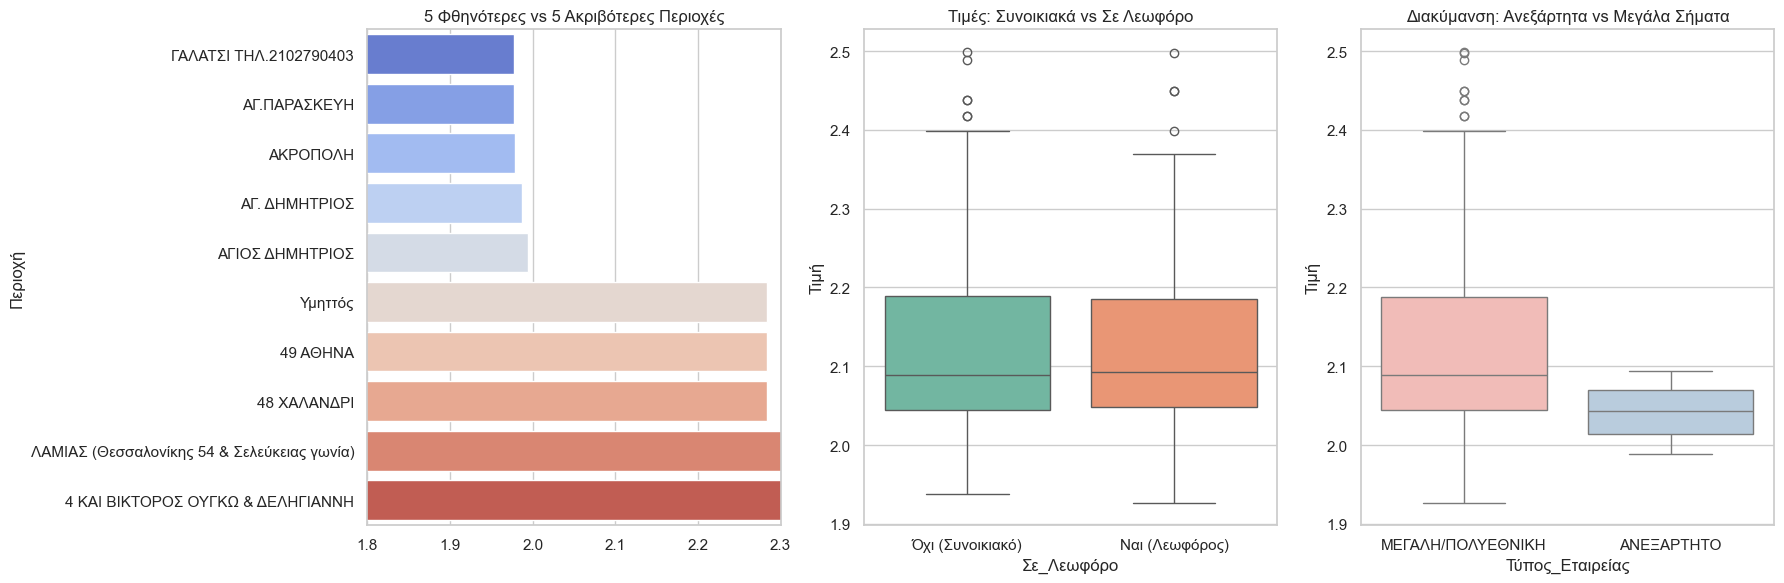

In [4]:
if 'Τύπος_Εταιρείας' not in df.columns:
    df['Τύπος_Εταιρείας'] = df['Εταιρεία'].apply(lambda x: 'ΑΝΕΞΑΡΤΗΤΟ' if 'ΑΝΕΞΑΡΤΗΤΟ' in str(x).upper() else 'ΜΕΓΑΛΗ/ΠΟΛΥΕΘΝΙΚΗ')

# Δημιουργία ενός καμβά με 3 "υπο-γραφήματα"
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Γράφημα 1: Περιοχές
df_areas = df[df['Περιοχή'] != 'ΑΓΝΩΣΤΟ']
area_prices = df_areas.groupby('Περιοχή')['Τιμή'].mean().sort_values()
top_bottom_areas = pd.concat([area_prices.head(5), area_prices.tail(5)])
# Προστέθηκε το hue και legend=False για να φύγει το warning
sns.barplot(x=top_bottom_areas.values, y=top_bottom_areas.index, ax=axes[0], hue=top_bottom_areas.index, palette="coolwarm", legend=False)
axes[0].set_title("5 Φθηνότερες vs 5 Ακριβότερες Περιοχές")
axes[0].set_xlim(1.8, 2.3) 

# Γράφημα 2: Λεωφόροι vs Συνοικιακά 
sns.boxplot(x='Σε_Λεωφόρο', y='Τιμή', data=df, ax=axes[1], hue='Σε_Λεωφόρο', palette="Set2", legend=False)
axes[1].set_title("Τιμές: Συνοικιακά vs Σε Λεωφόρο")
axes[1].set_xticks([0, 1]) # Διορθώνει το UserWarning
axes[1].set_xticklabels(['Όχι (Συνοικιακό)', 'Ναι (Λεωφόρος)'])

# Γράφημα 3: Ανεξάρτητα vs Μεγάλες Εταιρείες
sns.boxplot(x='Τύπος_Εταιρείας', y='Τιμή', data=df, ax=axes[2], hue='Τύπος_Εταιρείας', palette="Pastel1", legend=False)
axes[2].set_title("Διακύμανση: Ανεξάρτητα vs Μεγάλα Σήματα")

plt.tight_layout()
plt.show()

## Εκπαίδευση Αλγορίθμου Machine Learning (Random Forest)
Εκπαιδεύουμε το μοντέλο μας χρησιμοποιώντας One-Hot Encoding για τα κειμενικά χαρακτηριστικά.

In [5]:
# Επιλογή Χαρακτηριστικών (Features) και Στόχου (Target)
features = ['Είναι_Premium', 'Σε_Λεωφόρο', 'Εταιρεία', 'Περιοχή']
target = 'Τιμή'

# One-Hot Encoding
X = pd.get_dummies(df[features], drop_first=True)
y = df[target]

print(f"Το μοντέλο θα εκπαιδευτεί με {X.shape[1]} διαφορετικά χαρακτηριστικά.\n")

# Train/Test Split (80% Εκπαίδευση - 20% Τεστ)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ΕΚΠΑΙΔΕΥΣΗ MACHINE LEARNING
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Αξιολόγηση 
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)

print(f"Το νέο Μέσο Απόλυτο Σφάλμα (MAE) είναι: ±{mae:.4f}€ ανά λίτρο.\n")

# Εμφάνιση των πρώτων 5 προβλέψεων δίπλα στις πραγματικές
results = pd.DataFrame({
    'Πραγματική Τιμή': y_test.values[:5], 
    'Πρόβλεψη ML': predictions[:5],
    'Απόκλιση': abs(y_test.values[:5] - predictions[:5])
})
print("Δείγμα Προβλέψεων στο Test Set:")
display(results)

Το μοντέλο θα εκπαιδευτεί με 163 διαφορετικά χαρακτηριστικά.

Το νέο Μέσο Απόλυτο Σφάλμα (MAE) είναι: ±0.0315€ ανά λίτρο.

Δείγμα Προβλέψεων στο Test Set:


,Πραγματική Τιμή,Πρόβλεψη ML,Απόκλιση
0,1.995,2.040410,0.045410
1,2.098,2.056436,0.041564
2,1.989,2.005608,0.016608
3,2.039,2.040586,0.001586
4,2.147,2.171069,0.024069
